Dataset loaded successfully!
Dataset Shape: (503, 14)


,Student_ID,Name,Gender,Department,Attendance_Percent,Study_Hours_Per_Day,Previous_Score,Assignment_Score,Internal_Marks,Sleep_Hours,Participation_Percent,Final_Score,Grade,Result
0,1001,Student_001,Male,IT,72.6,4.8,82.9,73.4,93.4,5.2,77.8,97.0,A+,Pass
1,1002,Student_002,Female,Mechanical,85.5,4.6,56.6,81.7,88.8,7.9,24.4,78.7,B,Pass
2,1003,Student_003,Male,Mechanical,65.2,2.1,46.7,51.4,51.8,6.5,82.3,65.9,C,Pass
3,1004,Student_004,Male,IT,76.3,5.8,90.5,58.1,81.6,5.6,72.3,74.6,B,Pass
4,1005,Student_005,Male,CSE,79.4,5.7,63.2,57.1,81.4,6.5,66.0,83.1,A,Pass



Column Names:
['Student_ID', 'Name', 'Gender', 'Department', 'Attendance_Percent', 'Study_Hours_Per_Day', 'Previous_Score', 'Assignment_Score', 'Internal_Marks', 'Sleep_Hours', 'Participation_Percent', 'Final_Score', 'Grade', 'Result']

Data Types:
Student_ID                 int64
Name                      object
Gender                    object
Department                object
Attendance_Percent       float64
Study_Hours_Per_Day      float64
Previous_Score           float64
Assignment_Score         float64
Internal_Marks           float64
Sleep_Hours              float64
Participation_Percent    float64
Final_Score              float64
Grade                     object
Result                    object
dtype: object

Missing Values:
Student_ID               0
Name                     0
Gender                   0
Department               0
Attendance_Percent       2
Study_Hours_Per_Day      3
Previous_Score           0
Assignment_Score         3
Internal_Marks           0
Sleep_Hours   

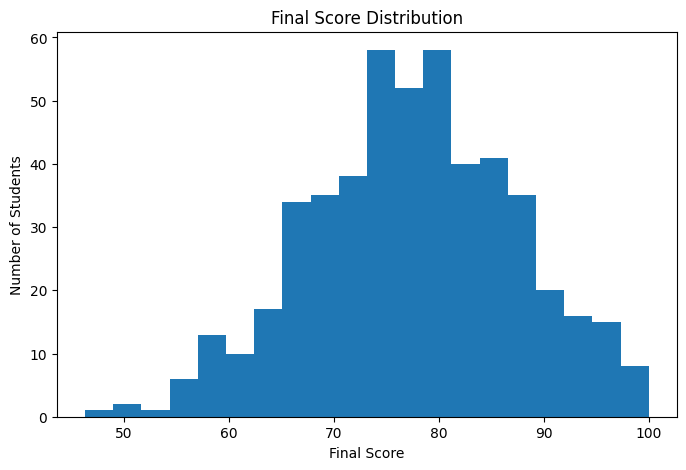

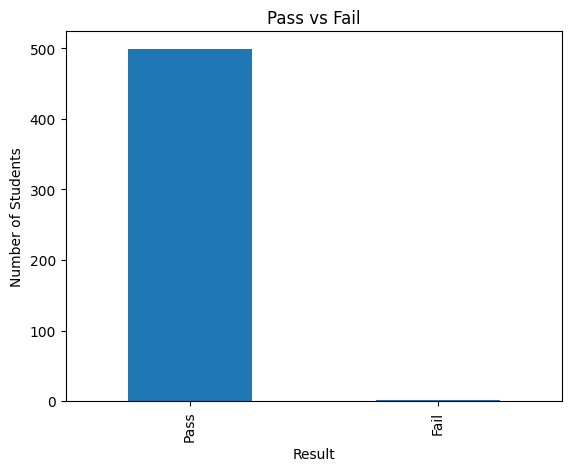

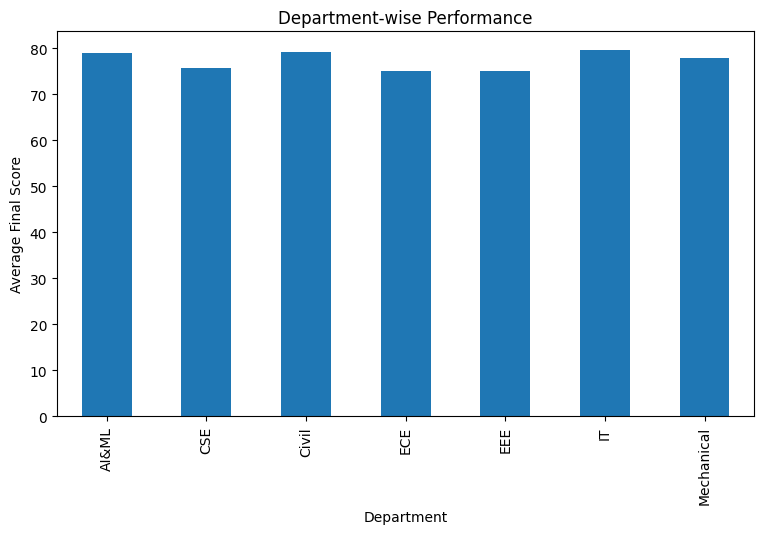

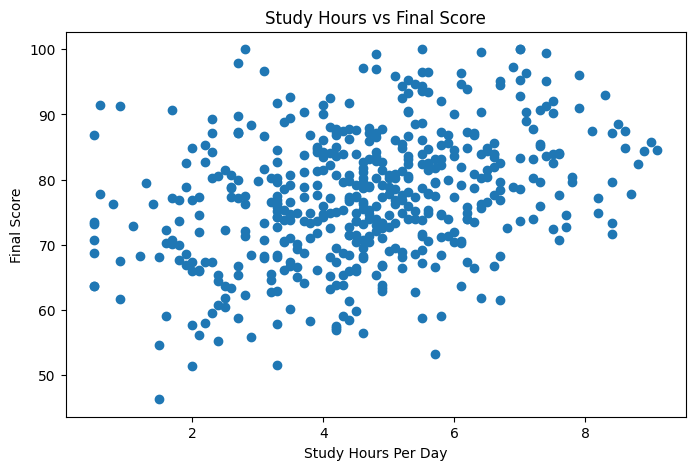

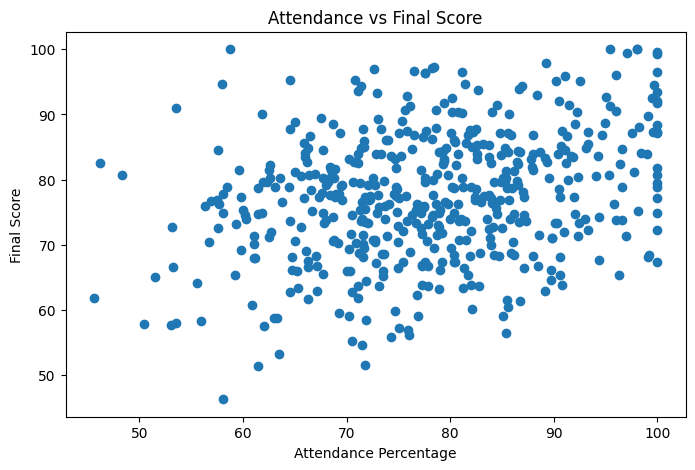


CORRELATION WITH FINAL SCORE
Final_Score              1.000000
Internal_Marks           0.354667
Study_Hours_Per_Day      0.341355
Attendance_Percent       0.297080
Previous_Score           0.282129
Assignment_Score         0.253808
Participation_Percent    0.093565
Sleep_Hours             -0.030304
Student_ID              -0.068897
Name: Final_Score, dtype: float64

FEATURES
['Attendance_Percent', 'Study_Hours_Per_Day', 'Previous_Score', 'Assignment_Score', 'Internal_Marks', 'Sleep_Hours', 'Participation_Percent']

TARGET
Final_Score

TRAIN TEST SPLIT
Training data: (400, 7)
Testing data : (100, 7)

LINEAR REGRESSION
MAE : 6.32
MSE : 64.2
RMSE: 8.01
R²  : 0.45

DECISION TREE REGRESSOR
MAE : 10.4
MSE : 163.31
RMSE: 12.78
R²  : -0.41

RANDOM FOREST REGRESSOR
MAE : 6.93
MSE : 73.28
RMSE: 8.56
R²  : 0.37

MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,6.32,64.20,8.01,0.45
1,Decision Tree,10.40,163.31,12.78,-0.41
2,Random Forest,6.93,73.28,8.56,0.37



🏆 BEST MODEL
Model : Linear Regression
MAE   : 6.32
MSE   : 64.2
RMSE  : 8.01
R²    : 0.45

FEATURE IMPORTANCE


,Feature,Importance
4,Internal_Marks,0.193543
1,Study_Hours_Per_Day,0.191011
2,Previous_Score,0.162845
3,Assignment_Score,0.149193
0,Attendance_Percent,0.147684
6,Participation_Percent,0.095834
5,Sleep_Hours,0.059890


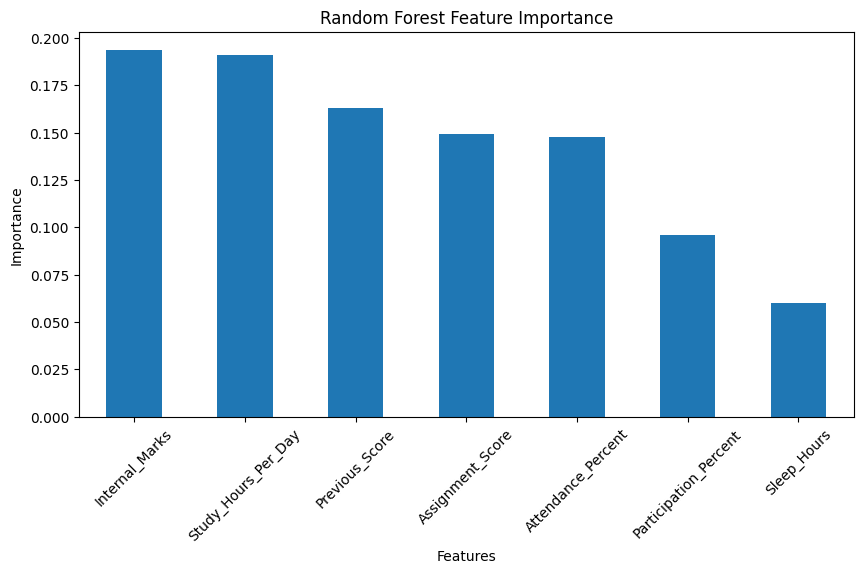

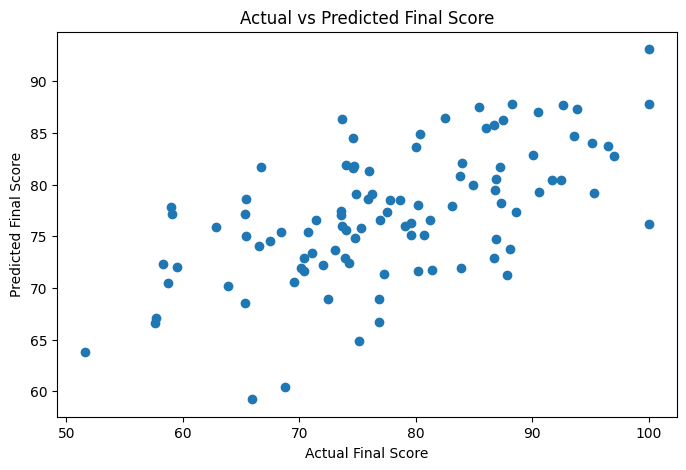



   STUDENT PERFORMANCE ANALYTICS
Total Students : 500
Average Final Score : 77.43
Highest Final Score : 100.0
Lowest Final Score : 46.3
Pass Students : 499
Fail Students : 1
Best ML Model : Linear Regression
Best R² Score : 0.45

Top Important Features:
               Feature  Importance
4       Internal_Marks    0.193543
1  Study_Hours_Per_Day    0.191011
2       Previous_Score    0.162845

FINAL CONCLUSION
Three regression models were used to predict student Final Score.
The models were Linear Regression, Decision Tree Regressor and Random Forest Regressor.
The models were evaluated using MAE, MSE, RMSE and R².
The model with the highest R² score was selected as the best model.
Feature importance was analyzed to identify the important factors affecting student performance.


In [3]:
# ============================================================
# STUDENT PERFORMANCE ANALYTICS
# ============================================================

# STEP 1 — LOAD DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Load CSV file
df = pd.read_csv("/content/student_performance_analytics_500.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


# ============================================================
# STEP 2 — CHECK DATA
# ============================================================

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())


# ============================================================
# STEP 3 — DATA CLEANING
# ============================================================

# Fill missing numerical values with median

numeric_columns = df.select_dtypes(include="number").columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())


# Remove duplicate records

df = df.drop_duplicates()


print("\nAfter Cleaning")
print("----------------")

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("Final Dataset Shape:", df.shape)


# ============================================================
# STEP 4 — EDA (EXPLORATORY DATA ANALYSIS)
# ============================================================

print("\nFINAL SCORE STATISTICS")
print("=======================")

print(df["Final_Score"].describe())


# Topper

topper = df.loc[df["Final_Score"].idxmax()]

print("\nTOPPER")
print("======")
print("Name       :", topper["Name"])
print("Department :", topper["Department"])
print("Final Score:", topper["Final_Score"])
print("Grade      :", topper["Grade"])


# Lowest scorer

lowest = df.loc[df["Final_Score"].idxmin()]

print("\nLOWEST SCORER")
print("=============")
print("Name       :", lowest["Name"])
print("Department :", lowest["Department"])
print("Final Score:", lowest["Final_Score"])
print("Grade      :", lowest["Grade"])


# Pass / Fail

print("\nPASS / FAIL")
print("===========")

result_count = df["Result"].value_counts()

print(result_count)


# Pass percentage

pass_percentage = (df["Result"].eq("Pass").sum() / len(df)) * 100

print("\nPass Percentage:",
      round(pass_percentage, 2), "%")


# Grade distribution

print("\nGRADE DISTRIBUTION")
print("==================")

print(df["Grade"].value_counts().sort_index())


# Department-wise average

print("\nDEPARTMENT-WISE AVERAGE")
print("=======================")

department_average = (
    df.groupby("Department")["Final_Score"]
    .mean()
    .sort_values(ascending=False)
)

print(department_average.round(2))


# ============================================================
# STEP 5 — VISUALIZATION
# ============================================================

# 1. Final Score Distribution

plt.figure(figsize=(8, 5))

plt.hist(df["Final_Score"], bins=20)

plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.title("Final Score Distribution")

plt.show()


# 2. Pass vs Fail

df["Result"].value_counts().plot(kind="bar")

plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.title("Pass vs Fail")

plt.show()


# 3. Department-wise Average

df.groupby("Department")["Final_Score"].mean().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.xlabel("Department")
plt.ylabel("Average Final Score")
plt.title("Department-wise Performance")

plt.show()


# 4. Study Hours vs Final Score

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Study_Hours_Per_Day"],
    df["Final_Score"]
)

plt.xlabel("Study Hours Per Day")
plt.ylabel("Final Score")
plt.title("Study Hours vs Final Score")

plt.show()


# 5. Attendance vs Final Score

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Attendance_Percent"],
    df["Final_Score"]
)

plt.xlabel("Attendance Percentage")
plt.ylabel("Final Score")
plt.title("Attendance vs Final Score")

plt.show()


# 6. Correlation

numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

print("\nCORRELATION WITH FINAL SCORE")
print("============================")

print(
    correlation["Final_Score"]
    .sort_values(ascending=False)
)


# ============================================================
# STEP 6 — FEATURE & TARGET SELECTION
# ============================================================

features = [
    "Attendance_Percent",
    "Study_Hours_Per_Day",
    "Previous_Score",
    "Assignment_Score",
    "Internal_Marks",
    "Sleep_Hours",
    "Participation_Percent"
]

X = df[features]

y = df["Final_Score"]


print("\nFEATURES")
print("=======")

print(X.columns.tolist())

print("\nTARGET")
print("======")

print("Final_Score")


# ============================================================
# STEP 7 — TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


print("\nTRAIN TEST SPLIT")
print("================")

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)


# ============================================================
# STEP 8 — LINEAR REGRESSION
# ============================================================

model1 = LinearRegression()

model1.fit(X_train, y_train)


# Prediction

y_pred1 = model1.predict(X_test)


# Evaluation

mae1 = mean_absolute_error(y_test, y_pred1)

mse1 = mean_squared_error(y_test, y_pred1)

rmse1 = np.sqrt(mse1)

r2_1 = r2_score(y_test, y_pred1)


print("\nLINEAR REGRESSION")
print("=================")

print("MAE :", round(mae1, 2))
print("MSE :", round(mse1, 2))
print("RMSE:", round(rmse1, 2))
print("R²  :", round(r2_1, 2))


# ============================================================
# STEP 9 — DECISION TREE REGRESSOR
# ============================================================

model2 = DecisionTreeRegressor(
    random_state=42
)

model2.fit(X_train, y_train)


# Prediction

y_pred2 = model2.predict(X_test)


# Evaluation

mae2 = mean_absolute_error(y_test, y_pred2)

mse2 = mean_squared_error(y_test, y_pred2)

rmse2 = np.sqrt(mse2)

r2_2 = r2_score(y_test, y_pred2)


print("\nDECISION TREE REGRESSOR")
print("======================")

print("MAE :", round(mae2, 2))
print("MSE :", round(mse2, 2))
print("RMSE:", round(rmse2, 2))
print("R²  :", round(r2_2, 2))


# ============================================================
# STEP 10 — RANDOM FOREST REGRESSOR
# ============================================================

model3 = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model3.fit(X_train, y_train)


# Prediction

y_pred3 = model3.predict(X_test)


# Evaluation

mae3 = mean_absolute_error(y_test, y_pred3)

mse3 = mean_squared_error(y_test, y_pred3)

rmse3 = np.sqrt(mse3)

r2_3 = r2_score(y_test, y_pred3)


print("\nRANDOM FOREST REGRESSOR")
print("======================")

print("MAE :", round(mae3, 2))
print("MSE :", round(mse3, 2))
print("RMSE:", round(rmse3, 2))
print("R²  :", round(r2_3, 2))


# ============================================================
# STEP 11 — MODEL COMPARISON
# ============================================================

results = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "MAE": [
        mae1,
        mae2,
        mae3
    ],

    "MSE": [
        mse1,
        mse2,
        mse3
    ],

    "RMSE": [
        rmse1,
        rmse2,
        rmse3
    ],

    "R2 Score": [
        r2_1,
        r2_2,
        r2_3
    ]
})


print("\nMODEL COMPARISON")
print("================")

display(results.round(2))


# ============================================================
# STEP 12 — BEST MODEL
# ============================================================

# Highest R² is considered best

best_model = results.loc[
    results["R2 Score"].idxmax()
]


print("\n🏆 BEST MODEL")
print("=============")

print("Model :", best_model["Model"])
print("MAE   :", round(best_model["MAE"], 2))
print("MSE   :", round(best_model["MSE"], 2))
print("RMSE  :", round(best_model["RMSE"], 2))
print("R²    :", round(best_model["R2 Score"], 2))


# ============================================================
# STEP 13 — FEATURE IMPORTANCE
# ============================================================

# Random Forest feature importance

feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": model3.feature_importances_

})


feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)


print("\nFEATURE IMPORTANCE")
print("==================")

display(feature_importance)


# Feature importance graph

feature_importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")

plt.xticks(rotation=45)

plt.show()


# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred3
)

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")

plt.title("Actual vs Predicted Final Score")

plt.show()


# ============================================================
# STEP 14 — FINAL CONCLUSION
# ============================================================

print("\n")
print("==========================================")
print("   STUDENT PERFORMANCE ANALYTICS")
print("==========================================")

print("Total Students :", len(df))

print(
    "Average Final Score :",
    round(df["Final_Score"].mean(), 2)
)

print(
    "Highest Final Score :",
    round(df["Final_Score"].max(), 2)
)

print(
    "Lowest Final Score :",
    round(df["Final_Score"].min(), 2)
)

print(
    "Pass Students :",
    (df["Result"] == "Pass").sum()
)

print(
    "Fail Students :",
    (df["Result"] == "Fail").sum()
)

print(
    "Best ML Model :",
    best_model["Model"]
)

print(
    "Best R² Score :",
    round(best_model["R2 Score"], 2)
)

print("\nTop Important Features:")

print(
    feature_importance.head(3)
)


print("\n==========================================")
print("FINAL CONCLUSION")
print("==========================================")

print(
    "Three regression models were used to predict "
    "student Final Score."
)

print(
    "The models were Linear Regression, "
    "Decision Tree Regressor and Random Forest Regressor."
)

print(
    "The models were evaluated using MAE, MSE, RMSE and R²."
)

print(
    "The model with the highest R² score was selected "
    "as the best model."
)

print(
    "Feature importance was analyzed to identify "
    "the important factors affecting student performance."
)